# Body fat: automatic specification with `autospec`

Body measurements can predict DEXA fat when a scan is unavailable. We use
`autospec` to choose effect shapes and a stopping iteration, inspect the
preliminary tree ensemble's proposals, and predict women held outside the
entire search. The fitted effects describe associations between measurements;
they do not identify effects of changing a woman's body measurements.

The data contain 71 women and nine predictors, distributed with `TH.data` and
used in the mboost tutorial {cite:p}`hofner2014mboost_tutorial`. The response is
`DEXfat`, in kg; age is in years, circumferences and breadths are in cm, and
`anthro3a` through `anthro4` are derived anthropometric indices. Correlated
measurements can substitute for each other, so variable ranking is not the
main target. The analysis targets squared prediction error for another woman
from the same population.

:::{admonition} Study design
:class: dropdown

The sampling unit is one woman; rows are treated as independent. A fixed
random split reserves 18 women for evaluation and uses 53 for fitting and
five-fold tuning. The estimand is test mean squared error in kg², conditional
on that training split. Its reported standard error reflects the 18 test
losses, not uncertainty from repeating training or selecting a specification.
The claim is predictive and descriptive; this small test set cannot establish
population-wide superiority of one workflow.
:::

## Training and test data

The split occurs before column screening or tuning. The test responses enter
only the final evaluation. Polars keeps the named measurements attached to
their values when rows are selected.


In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")


RendererRegistry.enable('svg')

In [2]:
bf = mb.datasets.bodyfat(output="polars")
predictors = [name for name in bf.columns if name != "DEXfat"]
order = np.random.default_rng(2026).permutation(bf.height)
train = bf[order[:53]]
test = bf[order[53:]]
print(f"Training: {train.height} women; test: {test.height} women")
display(train.select("DEXfat", "age", "waistcirc", "hipcirc").head())


Training: 53 women; test: 18 women


DEXfat,age,waistcirc,hipcirc
f64,i64,f64,f64
20.84,27,66.5,100.0
46.99,57,117.0,116.0
42.01,49,100.5,112.0
42.76,62,103.0,125.0
13.7,19,68.0,88.0


Waist and hip circumference measure related aspects of body size; breadths
and the derived indices supply other information about body composition.
All nine are available before a DEXA prediction is made. They are eligible
predictors, while `DEXfat` itself is excluded from the feature frame.

## Specification and stopping iteration

`Gaussian()` specifies squared-error fitting for a continuous response in kg.
It expresses our prediction target directly rather than inferring a count or
positive-response family from storage type. `budget=200` bounds the reported
search cost, and `seed=4` fixes the five training folds. `preexploration="native"`
fits one preliminary tree ensemble to prioritize columns and propose shapes.
The default `interactions="report"` reports pair leads without adding them.
`rec.fit(train)` replays the chosen specification, iteration and learning rate.


In [3]:
rec = mb.autospec(train, "DEXfat", family=mb.Gaussian(), budget=200,
                  seed=4, preexploration="native", interactions="report")
fit = rec.fit(train)
print(rec.formula)
print(f"Stopping iteration: {rec.mstop}; learning rate: {rec.control.nu}")


DEXfat ~ bbs(waistcirc, df=4.0) + bbs(hipcirc, df=4.0) + bbs(kneebreadth, df=4.0) + bbs(anthro3a, df=4.0) + bbs(anthro3b, df=4.0) + bbs(anthro3c, df=4.0)
Stopping iteration: 87; learning rate: 0.3


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 107 is within 5% of the search cap 107; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 106 is within 5% of the search cap 107; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 102 is within 5% of the search cap 107; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


The retained terms are smooth contributions for body measurements. Their
stopping iteration is {eval}`int(rec.mstop)`. A preliminary importance rank
explains which shapes were considered first; it is not a rank of independent
biological causes. The table distinguishes that preliminary information from
the held-out comparison that chose each shape.


In [4]:
screen = rec.evidence["preexploration"]
shape_choices = {row.column: row.chosen for row in rec.evidence["shapes"]}
rows = [{"measurement": row["column"], "importance": row["importance"],
         "proposed": ", ".join(row["shapes"]),
         "chosen": shape_choices.get(row["column"], "not compared")}
        for row in screen["columns"]]
screen_frame = pl.DataFrame(rows).sort("importance", descending=True)

table(screen_frame, title="Body-fat shape proposals and comparisons",
      subtitle="Training data only; permutation loss increase in kg²",
      stub="measurement", stubhead="Measurement",
      labels={"importance": "Loss increase (kg²)", "proposed": "Proposed shapes",
              "chosen": "CV choice"},
      notes=["Permutation loss measures the preliminary ensemble's reliance on a column.",
             "CV choice precedes deselection: a chosen learner may still be absent from the final formula.",
             "The incumbent and declared terms remain eligible; these are point diagnostics, not confidence statements."])


GT(_tbl_data=shape: (9, 4)
┌──────────────┬────────────┬──────────────────┬────────┐
│ measurement  ┆ importance ┆ proposed         ┆ chosen │
│ ---          ┆ ---        ┆ ---              ┆ ---    │
│ str          ┆ f64        ┆ str              ┆ str    │
╞══════════════╪════════════╪══════════════════╪════════╡
│ waistcirc    ┆ 29.758372  ┆ bols, bbs, btree ┆ bbs    │
│ hipcirc      ┆ 16.330583  ┆ bols, bbs, btree ┆ bbs    │
│ anthro3c     ┆ 10.591191  ┆ bols, bbs, btree ┆ bbs    │
│ anthro3b     ┆ 6.499624   ┆ bols, bbs, btree ┆ bbs    │
│ kneebreadth  ┆ 4.830473   ┆ bols, bbs, btree ┆ bbs    │
│ age          ┆ 1.912848   ┆ bols, bbs, btree ┆ btree  │
│ anthro3a     ┆ 1.378611   ┆ bols, bbs, btree ┆ bbs    │
│ anthro4      ┆ 0.44352    ┆ bols, bbs, btree ┆ bbs    │
│ elbowbreadth ┆ 0.245345   ┆ bols, bbs, btree ┆ bbs    │
└──────────────┴────────────┴──────────────────┴────────┘, _body=<great_tables._gt_data.Body object at 0x10c6793d0>, _boxhead=Boxhead([ColInfo(var='measurement', type=<ColInfoTypeEnum.stub: 2>, column_label='measurement', column_align='left', column_width=None), ColInfo(var='importance', type=<ColInfoTypeEnum.default: 1>, column_label='Loss increase (kg²)', column_align='right', column_width=None), ColInfo(var='proposed', type=<ColInfoTypeEnum.default: 1>, column_label='Proposed shapes', column_align='left', column_width=None), ColInfo(var='chosen', type=<ColInfoTypeEnum.default: 1>, column_label='CV choice', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e7da3f0>, _spanners=Spanners([]), _heading=Heading(title='Body-fat shape proposals and comparisons', subtitle='Training data only; permutation loss increase in kg²', preheader=None), _stubhead='Measurement', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e6e77a0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10e7a7650>, _source_notes=["Permutation loss measures the preliminary ensemble's reliance on a column.", 'CV choice precedes deselection: a chosen learner may still be absent from the final formula.', 'The incumbent and declared terms remain eligible; these are point diagnostics, not confidence statements.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10e7a79e0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c5831d0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10e0aa570>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True

A large permutation loss means that shuffling a measurement damages the
preliminary model's prediction. Correlation can spread that reliance over
several measurements or make a substitute appear unimportant. The final
formula, rather than this ranking, states which terms survived deselection.

## Partial effect of waist circumference

`partial_effects` returns a learner's contribution to the additive predictor.
For a Gaussian model that contribution is in kg. We center it over the display
grid so the vertical axis describes changes relative to the grid mean; the
intercept and other measurements supply the rest of a prediction.


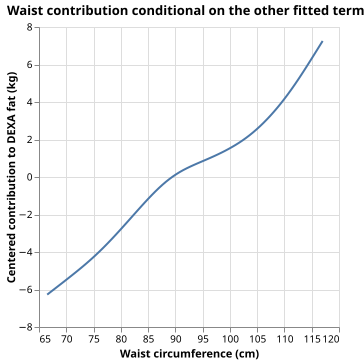

In [5]:
waist = fit.partial_effects(which="waistcirc", n_points=80)
waist_x, waist_effect = next(iter(waist.values()))
effect = np.asarray(waist_effect).ravel()
curve = pl.DataFrame({"waist": np.asarray(waist_x).ravel(),
                      "effect": effect - effect.mean()})
chart = alt.Chart(curve).mark_line().encode(
    x=alt.X("waist:Q", title="Waist circumference (cm)"),
    y=alt.Y("effect:Q", title="Centered contribution to DEXA fat (kg)"),
).properties(title="Waist contribution conditional on the other fitted terms")
display(chart)


The curve summarizes the waist term conditional on the other fitted
measurements. Correlated predictors make its allocation unstable across
training samples. The figure has no confidence band and supports neither a
causal interpretation nor a claim that waist is the uniquely important measure.

## Predictions for held-out women

The feature frame passed to `predict` omits the response. The first five
predictions illustrate the output; all 18 held-out women contribute to the
subsequent error estimate.


In [6]:
predicted = np.asarray(fit.predict(test.drop("DEXfat"), type="response")).ravel()
observed = test["DEXfat"].to_numpy()
predictions = pl.DataFrame({"woman": np.arange(1, test.height + 1),
                            "observed": observed, "predicted": predicted})
table(predictions.head(5), title="DEXA fat predictions for held-out women",
      subtitle="Observed and predicted body fat in kg", stub="woman", stubhead="Test row",
      labels={"observed": "Observed (kg)", "predicted": "Predicted (kg)"},
      notes=["These are point predictions; rows were excluded from the complete specification search."])


GT(_tbl_data=shape: (5, 3)
┌───────┬──────────┬───────────┐
│ woman ┆ observed ┆ predicted │
│ ---   ┆ ---      ┆ ---       │
│ i64   ┆ f64      ┆ f64       │
╞═══════╪══════════╪═══════════╡
│ 1     ┆ 26.36    ┆ 29.468083 │
│ 2     ┆ 25.16    ┆ 20.171338 │
│ 3     ┆ 38.65    ┆ 36.36312  │
│ 4     ┆ 31.61    ┆ 35.386368 │
│ 5     ┆ 21.07    ┆ 20.988937 │
└───────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10e7a77d0>, _boxhead=Boxhead([ColInfo(var='woman', type=<ColInfoTypeEnum.stub: 2>, column_label='woman', column_align='right', column_width=None), ColInfo(var='observed', type=<ColInfoTypeEnum.default: 1>, column_label='Observed (kg)', column_align='right', column_width=None), ColInfo(var='predicted', type=<ColInfoTypeEnum.default: 1>, column_label='Predicted (kg)', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e0e09e0>, _spanners=Spanners([]), _heading=Heading(title='DEXA fat predictions for held-out women', subtitle='Observed and predicted body fat in kg', preheader=None), _stubhead='Test row', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ba98bf0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10e0e0b30>, _source_notes=['These are point predictions; rows were excluded from the complete specification search.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111c3d7c0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c353710>, <great_tables._gt_data.FormatInfo object at 0x111d17fb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x111d173e0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2p

## Extension: a linear reference

For context, fit a linear contribution for every measurement and tune its
stopping iteration on the same training rows. The reference and autospec each
use their own tuned model. Comparing them on the untouched test set assesses
the two workflows; it does not isolate a causal effect of screening alone.


In [7]:
linear_formula = "DEXfat ~ " + " + ".join(f"bols({name})" for name in predictors)
linear = mb.tune_mstop(linear_formula, train, family=mb.Gaussian(), seed=4).model
linear_pred = np.asarray(linear.predict(test.drop("DEXfat"))).ravel()
mean_pred = np.repeat(train["DEXfat"].mean(), test.height)

loss_rows = []
for name, prediction in (("Training mean", mean_pred), ("Tuned linear model", linear_pred),
                         ("autospec with native screening", predicted)):
    loss = (observed - prediction) ** 2
    loss_rows.append({"method": name, "mse": float(loss.mean()),
                      "se": float(loss.std(ddof=1) / np.sqrt(loss.size))})
loss_frame = pl.DataFrame(loss_rows)
auto_mse = loss_rows[-1]["mse"]
linear_mse = loss_rows[1]["mse"]


In [8]:
table(loss_frame, title="Prediction error on the 18 reserved women",
      subtitle="Mean squared error in kg²; lower is better",
      labels={"mse": "MSE (kg²)", "se": "Conditional SE (kg²)"},
      spanners={"Test loss": ["mse", "se"]}, better={"mse": "min"},
      notes=["SE is the sample standard deviation of individual squared errors divided by √18.",
             "It conditions on the fitted models and this split; it excludes uncertainty from refitting and selection.",
             "Do not choose another screening policy from this test comparison and reuse the same error as independent validation."])


GT(_tbl_data=shape: (3, 3)
┌────────────────────────────────┬────────────┬───────────┐
│ method                         ┆ mse        ┆ se        │
│ ---                            ┆ ---        ┆ ---       │
│ str                            ┆ f64        ┆ f64       │
╞════════════════════════════════╪════════════╪═══════════╡
│ Training mean                  ┆ 133.736972 ┆ 54.1436   │
│ Tuned linear model             ┆ 21.3494    ┆ 10.726801 │
│ autospec with native screening ┆ 17.629292  ┆ 7.43561   │
└────────────────────────────────┴────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x111c0bfb0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE (kg²)', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Conditional SE (kg²)', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x111da0c20>, _spanners=Spanners([SpannerInfo(spanner_id='Test loss', spanner_level=0, spanner_label='Test loss', spanner_units=None, spanner_pattern=None, vars=['mse', 'se'], built=None)]), _heading=Heading(title='Prediction error on the 18 reserved women', subtitle='Mean squared error in kg²; lower is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e806bd0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10e7d9100>, _source_notes=['SE is the sample standard deviation of individual squared errors divided by √18.', 'It conditions on the fitted models and this split; it excludes uncertainty from refitting and selection.', 'Do not choose another screening policy from this test comparison and reuse the same error as independent validation.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111d16f60>, _formats=[<great_tables._gt_data.FormatInfo object at 0x111d08d40>, <great_tables._gt_data.FormatInfo object at 0x111da0d10>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x111da0da0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_s

Autospec's test MSE is {eval}`f"{auto_mse:.2f}"` kg², compared with
{eval}`f"{linear_mse:.2f}"` kg² for the tuned linear reference. These numbers
describe this split of a small data set. To compare screening engines more
broadly, repeat the entire search inside outer training folds; the
[screening benchmark](benchmark_preexploration.ipynb) illustrates paired
replication on simulated data with a known mean function.

`preexploration="off"` retains the full shape catalogue and the residual pair
screen. `preexploration="hessboost"` selects the optional engine when the
installed build includes it. For either setting, preliminary importance and the inner CV minimum use the
training data. Evaluate the selected model on reserved rows to estimate its
prediction error. The
[methodology chapter](../methodology/preexploration.ipynb) defines the diagnostics.


```{bibliography}
:filter: docname in docnames
```
